# Bank Customer Segmentation and Credit Risk: Part 3, Segmentation

In this notebook I group the bank's 4,500 customers by **how they use their accounts**, describe each group in plain language, and save the groups for the credit risk part.

**Approach:** the clustering uses **behaviour only**: money flows, balances and types of transactions. Demographics (age, gender, region) and products (cards, loans) are left out of the clustering and only used afterwards to describe the segments. That way the segments show *how* people bank, and any link to age or loans is a genuine finding rather than something I put in.

It uses the clean tables from notebook 01 and the decisions from notebook 02.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

## 1. Loading the data and applying the rules from step 2

From the time series analysis I carry over three decisions:
- **Leave out January**, because its cash and card withdrawals look rule-generated.
- **Leave out bank-generated transactions** (interest, fees, penalty interest), because they say nothing about the customer.
- **Don't use timing within the month**, because every customer's transfers follow the same schedule.

I also leave out **loan repayments**. Otherwise the clustering would partly just separate customers with a loan from those without, and in step 4 I want to compare loan risk *between* segments.

In [2]:
trans = pd.read_parquet("data/clean/trans.parquet")
daily_balance = pd.read_parquet("data/clean/daily_balance.parquet")
account_profile = pd.read_parquet("data/clean/account_profile.parquet")

excluded_purposes = ["interest credited", "statement fee", "penalty interest", "loan repayment"]
behaviour = trans[~trans["purpose"].isin(excluded_purposes) & (trans["date"].dt.month != 1)].copy()
behaviour["month"] = behaviour["date"].dt.to_period("M")

print(f"transactions used for segmentation: {len(behaviour):,} of {len(trans):,}")

transactions used for segmentation: 605,715 of 1,056,320


### Different lengths of history

Accounts were opened at different times between 1993 and 1997, so some have five years of history and others only one. Totals would make older accounts look more active just because they are older. So every feature is a **rate per month**, using the number of (non-January) months between the account's first transaction and December 1998.

In [3]:
all_months = pd.period_range("1993-01", "1998-12", freq="M")
non_january = all_months[all_months.month != 1]

first_month = trans.groupby("account_id")["date"].min().dt.to_period("M")
months_observed = first_month.apply(lambda first: (non_january >= first).sum())

months_observed.describe()[["min", "50%", "max"]]

min    12.0
50%    33.0
max    66.0
Name: date, dtype: float64

## 2. Building the features

One row per account, with seven candidate features:

| Feature | What it measures |
|---|---|
| `trans_per_month` | how active the account is |
| `inflow_per_month` | money coming in per month (CZK) |
| `outflow_per_month` | money going out per month (CZK) |
| `cash_share` | share of transactions that are cash deposits or withdrawals |
| `pension_share` | share of months in which a pension was received |
| `median_balance` | typical end-of-month balance (CZK) |
| `balance_volatility` | how much the end-of-month balance swings (standard deviation ÷ median) |

In [4]:
by_account = behaviour.groupby("account_id")
features = pd.DataFrame({"months": months_observed})

features["trans_per_month"] = by_account.size() / features["months"]

credits = behaviour[behaviour["direction"] == "credit"]
debits = behaviour[behaviour["direction"] == "debit"]
features["inflow_per_month"] = credits.groupby("account_id")["amount"].sum() / features["months"]
features["outflow_per_month"] = debits.groupby("account_id")["amount"].sum() / features["months"]

cash = behaviour[behaviour["operation"].isin(["cash deposit", "cash withdrawal"])]
features["cash_share"] = cash.groupby("account_id").size() / by_account.size()

pension = behaviour[behaviour["purpose"] == "pension"]
features["pension_share"] = pension.groupby("account_id")["month"].nunique() / features["months"]

# an account with no transactions of a type gets 0, not missing
features = features.fillna(0)

For the balance features I rebuild the end-of-month balances from notebook 02 (last end-of-day balance each month, carried forward into months without transactions), again leaving out January.

In [5]:
daily_balance["month"] = daily_balance["date"].dt.to_period("M")
month_end = (daily_balance.sort_values(["account_id", "date"])
                          .groupby(["account_id", "month"])["end_of_day_balance"].last()
                          .unstack("month")
                          .ffill(axis=1))
month_end = month_end.loc[:, month_end.columns.month != 1]

features["median_balance"] = month_end.median(axis=1)
features["balance_volatility"] = month_end.std(axis=1) / month_end.median(axis=1).abs()

features.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
months,4500.0,38.27,16.64,12.00,24.00,33.00,56.00,66.00
trans_per_month,4500.0,3.46,1.08,0.30,2.71,3.31,4.04,8.93
inflow_per_month,4500.0,17225.66,13307.80,452.17,5963.84,14254.67,24465.50,72703.33
outflow_per_month,4500.0,15223.20,12500.17,116.67,4823.14,12166.02,21629.00,66022.47
cash_share,4500.0,0.61,0.26,0.09,0.38,0.63,0.77,1.00
pension_share,4500.0,0.16,0.36,0.00,0.00,0.00,0.00,1.00
median_balance,4500.0,33617.89,13958.32,203.20,22210.60,31625.48,43027.36,88675.10
balance_volatility,4500.0,0.40,1.18,0.11,0.26,0.32,0.42,75.64


## 3. Checking the features

Before clustering, two checks: are any features measuring the same thing, and are there extreme values that would distort the clusters?

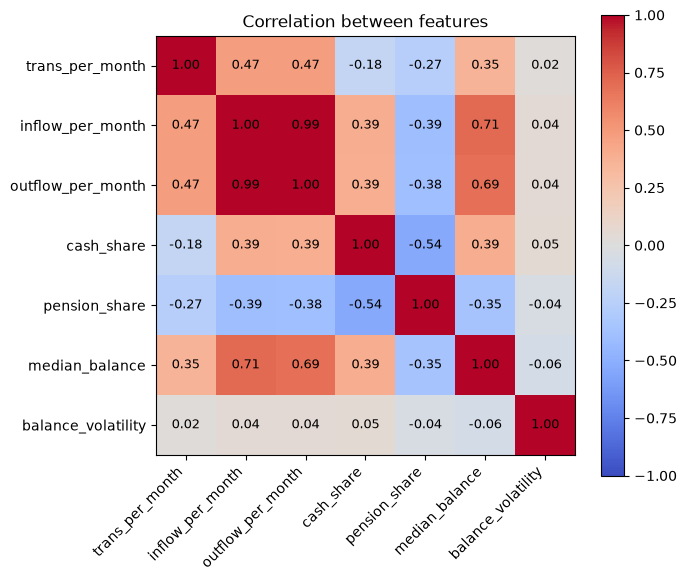

In [6]:
corr = features.drop(columns="months").corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(im)
plt.title("Correlation between features")
plt.tight_layout()
plt.show()

**Problem 1: inflow and outflow measure the same thing.** Their correlation is 0.99: over time, the money that comes into an account goes out again. Keeping both would give "how much money moves through the account" double weight in the clustering. I keep `inflow_per_month` and drop `outflow_per_month`.

In [7]:
print(features["balance_volatility"].describe(percentiles=[0.5, 0.99]).round(2))
features.sort_values("balance_volatility", ascending=False)[["median_balance", "balance_volatility"]].head()

count    4500.00
mean        0.40
std         1.18
min         0.11
50%         0.32
99%         1.14
max        75.64
Name: balance_volatility, dtype: float64


,median_balance,balance_volatility
account_id,,
2335,203.2,75.644929
5429,934.6,18.821038
1056,2452.0,8.059279
4127,2023.5,7.518190
2260,2959.2,4.750783


**Problem 2: balance volatility explodes for a few accounts.** It is the standard deviation divided by the median balance, so when the median balance is close to zero, the result becomes huge, even though the swings themselves may be small. The median account scores about 0.3, but the top accounts score up to about 75.

I keep the measure, because for most accounts it captures something useful, but **cap it at the 99th percentile**. The 45 most extreme accounts are set to the 99th-percentile value: they still count as "very volatile", without dominating the clustering.

In [8]:
volatility_cap = features["balance_volatility"].quantile(0.99)
features["balance_volatility"] = features["balance_volatility"].clip(upper=volatility_cap)
print(f"cap: {volatility_cap:.2f}")

cap: 1.14


**Skewed money features.** `inflow_per_month`, `median_balance` and `trans_per_month` have long right tails. k-means works with distances, so a few very large values would pull the clusters towards them. A **log transform** (`np.log1p`, which is log(1 + x) and works for 0) compresses the large values. Before taking the log I set any negative median balance to 0, because the log of a negative number isn't defined. No account actually has a negative median balance here (the lowest is about 200 CZK), but the safeguard means the code won't break on other data.

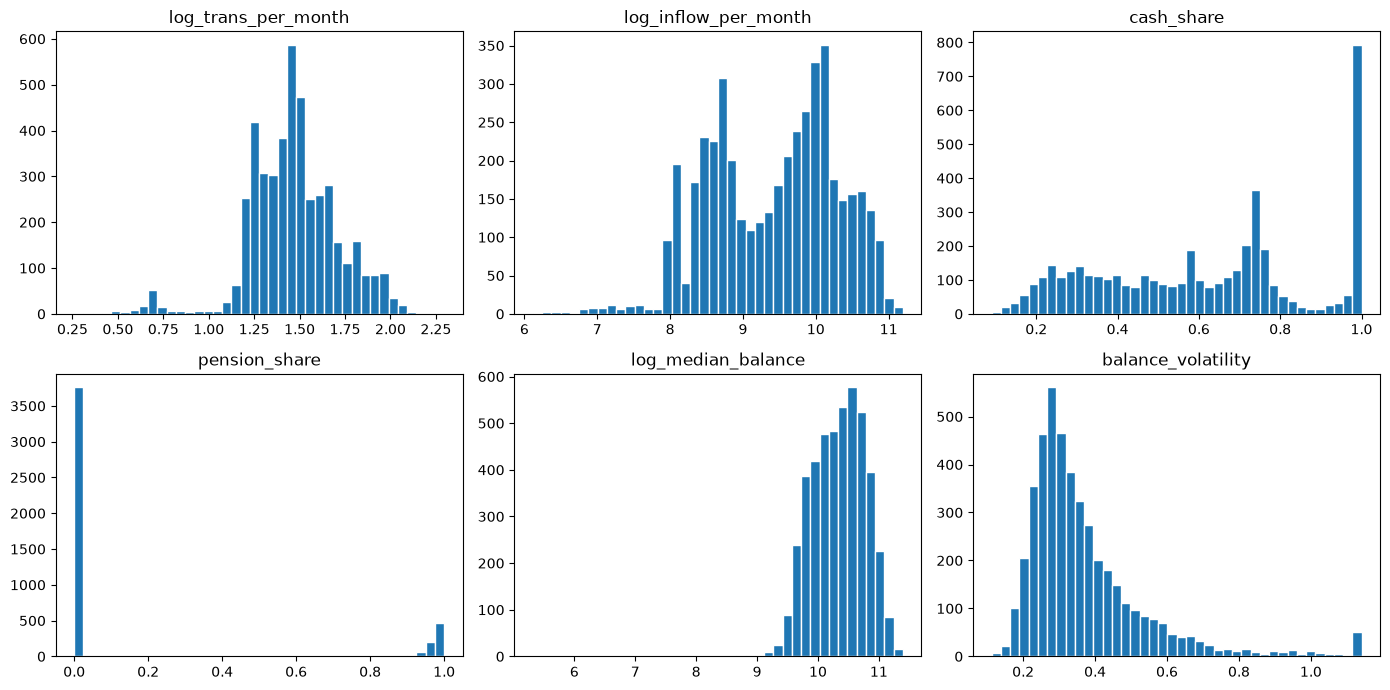

In [9]:
model_features = pd.DataFrame({
    "log_trans_per_month": np.log1p(features["trans_per_month"]),
    "log_inflow_per_month": np.log1p(features["inflow_per_month"]),
    "cash_share": features["cash_share"],
    "pension_share": features["pension_share"],
    "log_median_balance": np.log1p(features["median_balance"].clip(lower=0)),
    "balance_volatility": features["balance_volatility"],
})

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, model_features.columns):
    ax.hist(model_features[col], bins=40, edgecolor="white")
    ax.set_title(col)
plt.tight_layout()
plt.show()

`pension_share` has two clear groups: most accounts never receive a pension, and a separate group receives one almost every month. That is likely to become a segment on its own.

## 4. Scaling

k-means groups points that are close together, using distance. Without scaling, a feature like log inflow (values around 6–11) would count for more than `cash_share` (0 to 1), just because of its units. `StandardScaler` gives every feature a mean of 0 and a standard deviation of 1, so they all count equally.

In [10]:
scaler = StandardScaler()
X = scaler.fit_transform(model_features)

pd.DataFrame(X, columns=model_features.columns).describe().loc[["mean", "std"]].round(2)

,log_trans_per_month,log_inflow_per_month,cash_share,pension_share,log_median_balance,balance_volatility
mean,0.0,-0.0,0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


## 5. How many segments?

k-means needs the number of clusters, k, in advance. I try k = 2 to 8 and look at two measures:
- **Inertia** (the elbow method): the total distance from each account to its cluster centre. It always falls as k rises; the idea is to look for the point where adding clusters stops helping much.
- **Silhouette score**: from −1 to 1, how much closer each account is to its own cluster than to the next one. Higher is better.

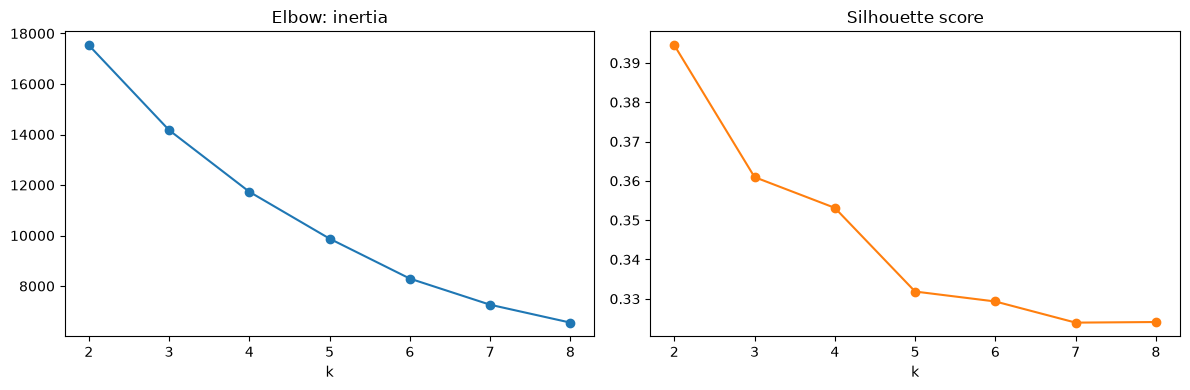

,inertia,silhouette,smallest_segment
k,,,
2,17534.966,0.394,1286
3,14174.286,0.361,726
4,11732.356,0.353,509
5,9876.853,0.332,390
6,8295.643,0.329,148
7,7261.424,0.324,132
8,6553.469,0.324,130


In [11]:
scores = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    scores.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X, km.labels_),
                   "smallest_segment": np.bincount(km.labels_).min()})
scores = pd.DataFrame(scores).set_index("k")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(scores.index, scores["inertia"], marker="o")
ax1.set_title("Elbow: inertia")
ax1.set_xlabel("k")
ax2.plot(scores.index, scores["silhouette"], marker="o", color="tab:orange")
ax2.set_title("Silhouette score")
ax2.set_xlabel("k")
plt.tight_layout()
plt.show()

scores.round(3)

Neither measure gives a clear answer, which is normal for real customer data:
- The **silhouette score** is highest at k = 2, then falls slowly. But two segments would be too coarse to do anything useful with.
- The **elbow** has no sharp bend; the curve flattens gradually.

So the choice is a judgement between statistics and usefulness. I choose **k = 4**:
- its silhouette (0.35) is close to k = 3 and clearly better than k = 5 and above,
- every segment is still large (500+ accounts), so each is worth acting on,
- and, as the next sections show, the four segments are easy to describe and very stable.

## 6. Fitting the model and describing the segments

In [12]:
k = 4
kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
features["cluster"] = kmeans.fit_predict(X)

profile_columns = ["trans_per_month", "inflow_per_month", "cash_share",
                   "pension_share", "median_balance", "balance_volatility"]
profile = features.groupby("cluster")[profile_columns].median()
profile.insert(0, "accounts", features["cluster"].value_counts())
profile.round(2)

,accounts,trans_per_month,inflow_per_month,cash_share,pension_share,median_balance,balance_volatility
cluster,,,,,,,
0,509,3.10,23580.94,1.00,0.00,29072.30,0.67
1,2342,3.64,21526.09,0.70,0.00,41448.70,0.32
2,740,2.72,5434.76,0.30,0.98,21235.45,0.28
3,909,2.96,4438.61,0.46,0.00,20413.00,0.29


The cluster numbers themselves mean nothing (and can change between computers or library versions), so I give each cluster a name based on its profile, using simple rules on the medians rather than hard-coding which number is which:
- the cluster where most months have a pension → **Pensioners**
- of the rest, the cluster that uses almost only cash → **Cash-only earners**
- of the remaining two, the one with the lower inflow → **Low-income customers**
- the last one → **Established savers**

In [13]:
names = {}
remaining = profile.copy()

pensioners = remaining["pension_share"].idxmax()
names[pensioners] = "Pensioners"
remaining = remaining.drop(pensioners)

cash_only = remaining["cash_share"].idxmax()
names[cash_only] = "Cash-only earners"
remaining = remaining.drop(cash_only)

low_income = remaining["inflow_per_month"].idxmin()
names[low_income] = "Low-income customers"
remaining = remaining.drop(low_income)

names[remaining.index[0]] = "Established savers"

features["segment"] = features["cluster"].map(names)
profile.index = profile.index.map(names)
segment_order = ["Established savers", "Cash-only earners", "Low-income customers", "Pensioners"]
profile = profile.loc[segment_order]
profile.round(2)

,accounts,trans_per_month,inflow_per_month,cash_share,pension_share,median_balance,balance_volatility
cluster,,,,,,,
Established savers,2342,3.64,21526.09,0.70,0.00,41448.70,0.32
Cash-only earners,509,3.10,23580.94,1.00,0.00,29072.30,0.67
Low-income customers,909,2.96,4438.61,0.46,0.00,20413.00,0.29
Pensioners,740,2.72,5434.76,0.30,0.98,21235.45,0.28


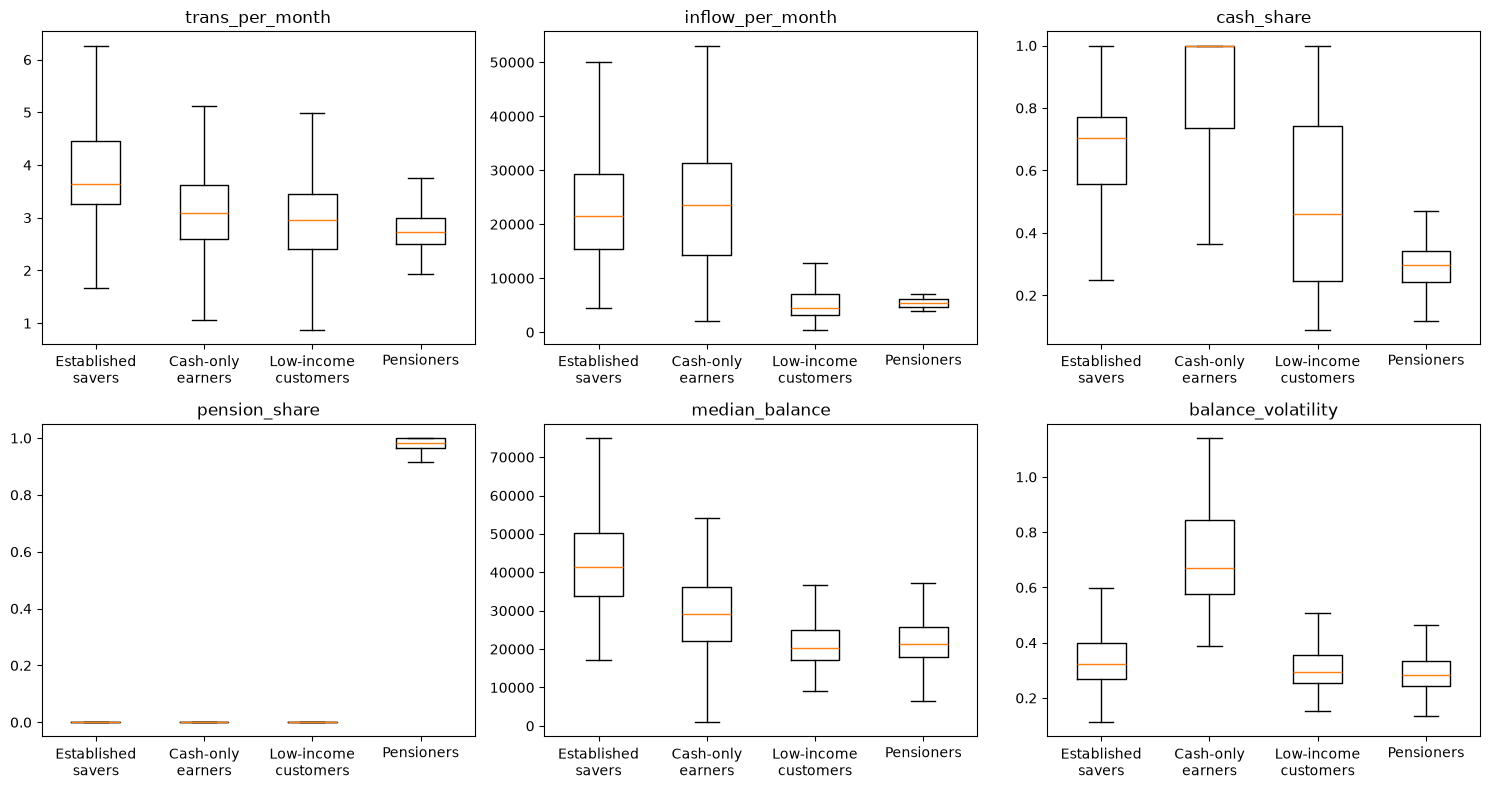

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, profile_columns):
    data = [features.loc[features["segment"] == s, col] for s in segment_order]
    ax.boxplot(data, showfliers=False)
    ax.set_xticks(range(1, 5), [s.replace(" ", "\n", 1) for s in segment_order])
    ax.set_title(col)
plt.tight_layout()
plt.show()

The four segments:

- **Established savers (2,342 accounts, 52%)**: the core of the bank. The most active accounts (about 3.6 transactions a month), good income (about 21,500 CZK a month coming in), the highest balances (median about 41,400 CZK) and a mix of cash and transfers. Their balances are steady.
- **Cash-only earners (509, 11%)**: similar income to the savers (about 23,600 CZK a month), but **almost all their transactions are cash**: they deposit cash and withdraw cash, and don't pay bills by transfer. Their balances swing about **twice as much** as any other segment's, and are lower than the savers'.
- **Low-income customers (909, 20%)**: by far the **least money coming in**, about 4,400 CZK a month, a fifth of the savers. Low but steady balances (about 20,400 CZK). This is the most mixed segment: some of these customers use mostly cash and others mostly transfers.
- **Pensioners (740, 16%)**: receive a pension in almost every month. Low income (about 5,400 CZK a month), low but very steady balances, and they mostly use **transfers rather than cash** (only 30% cash), because the pension arrives by transfer and the bills are paid the same way.

## 7. Seeing the segments

The model uses six features, which can't be drawn directly. **PCA** (principal component analysis) finds the two directions in which the data varies most, so the accounts can be shown on a flat chart. This is only for the picture: the clustering itself used all six features.

variance shown in the chart: 68%


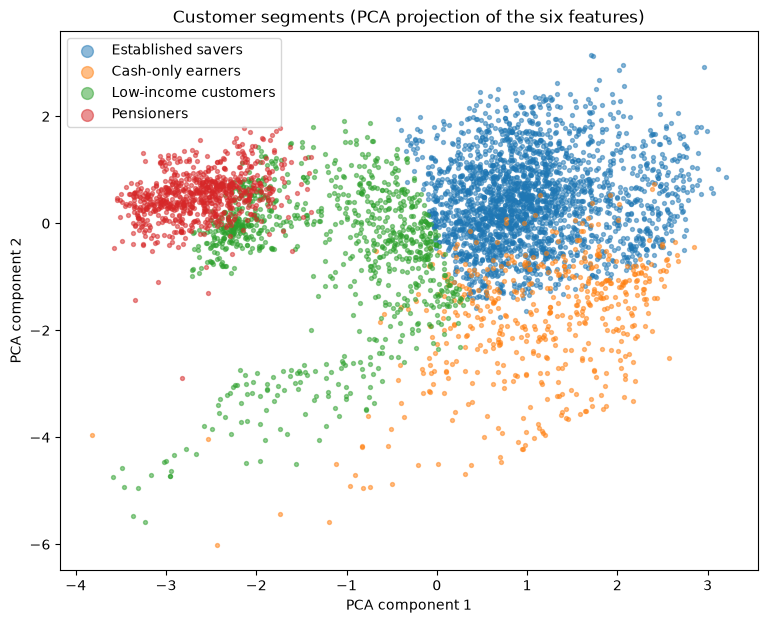

In [15]:
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X)
print(f"variance shown in the chart: {pca.explained_variance_ratio_.sum():.0%}")

plt.figure(figsize=(9, 7))
for segment in segment_order:
    mask = (features["segment"] == segment).values
    plt.scatter(coords[mask, 0], coords[mask, 1], s=8, alpha=0.5, label=segment)
plt.xlabel("PCA component 1")
plt.ylabel("PCA component 2")
plt.title("Customer segments (PCA projection of the six features)")
plt.legend(markerscale=3)
plt.show()

In [16]:
# what the two directions mean: how much each feature contributes
pd.DataFrame(pca.components_.T, index=model_features.columns, columns=["component 1", "component 2"]).round(2)

,component 1,component 2
log_trans_per_month,0.29,0.60
log_inflow_per_month,0.54,0.16
cash_share,0.41,-0.51
pension_share,-0.43,0.16
log_median_balance,0.47,0.27
balance_volatility,0.21,-0.51


The two PCA components show 68% of the variation in the six features, enough for a useful picture.
- **Component 1** is mainly about **money**: income, balance and cash use push to the right, and receiving a pension to the left.
- **Component 2** separates **active, transfer-based** accounts (up) from **cash-heavy, volatile** ones (down).

The Pensioners form a mostly separate group, with only a few Low-income customers next to them. Established savers, Low-income customers and Cash-only earners sit next to each other with overlapping edges, and the Low-income customers are spread out the most: customers don't fall into perfectly separate types, and accounts near the edges could reasonably belong to either neighbouring segment.

## 8. Who is in each segment?

Now the information that was **not** used for clustering: age, gender, where the customer lives, cards and loans. Any differences here are findings, not something the model was given.

In [17]:
described = account_profile.set_index("account_id").join(features["segment"])
described["has_card"] = described["card_type"].notna()
described["is_female"] = described["owner_gender"] == "F"

who = described.groupby("segment").agg(
    accounts=("segment", "size"),
    median_age=("owner_age", "median"),
    pct_female=("is_female", "mean"),
    district_salary=("district_avg_salary", "median"),
    pct_with_card=("has_card", "mean"),
    pct_with_loan=("has_loan", "mean"),
    loans=("has_loan", "sum"),
    bad_loans=("loan_is_bad", lambda s: int(s.fillna(False).sum())),
).loc[segment_order]
who["pct_bad_of_loans"] = who["bad_loans"] / who["loans"]

for col in ["pct_female", "pct_with_card", "pct_with_loan", "pct_bad_of_loans"]:
    who[col] = (100 * who[col]).round(1)
who

,accounts,median_age,pct_female,district_salary,pct_with_card,pct_with_loan,loans,bad_loans,pct_bad_of_loans
segment,,,,,,,,,
Established savers,2342,39.0,49.1,8980.0,33.1,21.7,508,17,3.3
Cash-only earners,509,39.0,46.2,9060.0,13.6,26.5,135,57,42.2
Low-income customers,909,37.0,50.1,8991.0,3.3,4.3,39,2,5.1
Pensioners,740,71.0,49.6,8985.5,2.4,0.0,0,0,<NA>


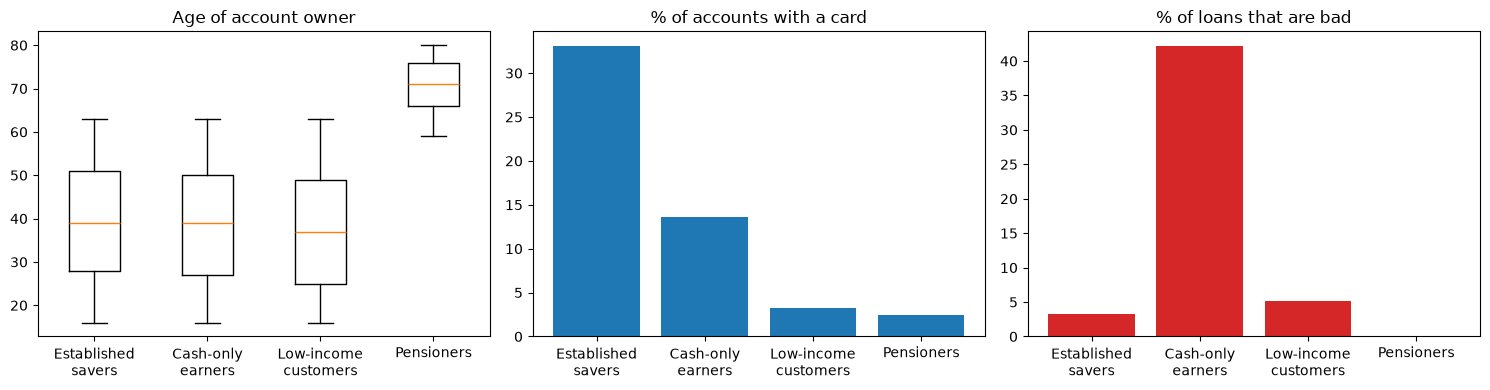

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].boxplot([described.loc[described["segment"] == s, "owner_age"] for s in segment_order])
axes[0].set_xticks(range(1, 5), [s.replace(" ", "\n", 1) for s in segment_order])
axes[0].set_title("Age of account owner")

axes[1].bar([s.replace(" ", "\n", 1) for s in segment_order], who["pct_with_card"])
axes[1].set_title("% of accounts with a card")

axes[2].bar([s.replace(" ", "\n", 1) for s in segment_order], who["pct_bad_of_loans"].fillna(0), color="tab:red")
axes[2].set_title("% of loans that are bad")

plt.tight_layout()
plt.show()

None of these columns was used for clustering, so these are genuine findings:
- **Pensioners are much older**: median age 71, against 37–39 in the other segments. The model found them from behaviour alone, which is a good sanity check that the segments are meaningful. **None of them has a loan**, and almost none has a card.
- **Gender and district salary** are almost identical in every segment, so the segments are not driven by gender or by where people live.
- **Cards** are mostly held by **Established savers** (33% have one); Low-income customers and Pensioners hardly have any.
- **Loans:** Established savers hold most of the loans (508 of 682), and only 3.3% of them are bad. **Cash-only earners** have 135 loans, and **57 of them (42%) are bad**. This one segment of 11% of customers holds **three quarters of all bad loans**.

**A caution about that last result.** The segments use each customer's **whole** history, including the period after any loan was granted. In notebook 02, I found that customers with a bad loan go negative after the loan, so their balances swing more. **Balance volatility** is one of the features that defines the Cash-only earners, so part of their high bad-loan rate is a *consequence* of the bad loans, not a warning sign. When I check the features separately, high volatility goes with 33% bad loans (against 2% otherwise), but heavy cash use on its own also goes with clearly more bad loans (27% against 6%), and cash use isn't caused by a bad loan in the same way.

So this table is a good **description** of where the bad loans are, but it can't be used to **predict** them. That is step 4, using only data from before each loan.

## 9. Are the segments stable?

k-means starts from random cluster centres, so different runs can end in different solutions. If the segments changed a lot from run to run, giving them business names would be misleading. I refit the model with five different random seeds and compare each result with the first using the **adjusted Rand index (ARI)**: 1 means identical groupings (even if the cluster numbers differ), 0 means no better than random.

In [19]:
runs = [KMeans(n_clusters=k, n_init=10, random_state=seed).fit_predict(X) for seed in [0, 1, 2, 3, 4]]

for seed, labels in zip([1, 2, 3, 4], runs[1:]):
    print(f"seed 0 vs seed {seed}: ARI = {adjusted_rand_score(runs[0], labels):.3f}")

seed 0 vs seed 1: ARI = 0.986
seed 0 vs seed 2: ARI = 0.989
seed 0 vs seed 3: ARI = 0.986
seed 0 vs seed 4: ARI = 0.999


In [20]:
# a tougher test: fit on a random 80% of accounts each time, then compare assignments for all accounts
rng = np.random.default_rng(42)
reference = features["cluster"].values
for i in range(5):
    sample = rng.choice(len(X), size=int(0.8 * len(X)), replace=False)
    km = KMeans(n_clusters=k, n_init=10, random_state=i).fit(X[sample])
    print(f"80% sample {i + 1}: ARI = {adjusted_rand_score(reference, km.predict(X)):.3f}")

80% sample 1: ARI = 0.975
80% sample 2: ARI = 0.983
80% sample 3: ARI = 0.975
80% sample 4: ARI = 0.984
80% sample 5: ARI = 0.774


- With different random seeds on the full data, the segments are almost identical every time (ARI 0.99).
- Fitting on random 80% samples is a harder test. Four of the five samples give almost the same segments (ARI 0.98), but one gives 0.77. In that run, part of the **Low-income customers** were grouped with the Cash-only earners instead. Pensioners and Established savers stayed the same.

So **Pensioners** and **Established savers** are very solid, and the boundary between **Cash-only earners** and **Low-income customers** is the least firm part of the segmentation. That fits the PCA chart, where those two groups touch. The segment names are still reasonable, but customers near that boundary could fit either group.

## 10. Saving the segments

In [21]:
to_save = features.reset_index()[["account_id", "segment"] + profile_columns]
to_save.to_parquet("data/clean/segments.parquet", index=False)
print(f"saved {len(to_save):,} accounts")
to_save["segment"].value_counts()

saved 4,500 accounts


segment
Established savers      2342
Low-income customers     909
Pensioners               740
Cash-only earners        509
Name: count, dtype: int64

## Summary of step 3

Using six behaviour features and k-means with k = 4, the bank's customers fall into four stable, easy-to-describe segments:

| Segment | Share | In one line | Possible action for the bank |
|---|---|---|---|
| Established savers | 52% | Good income, highest balances, mix of cash and transfers | Main market for cards and loans; loan risk is low (3% bad) |
| Cash-only earners | 11% | Similar income, but almost only cash and unstable balances | Look carefully before lending: 42% of their loans are bad. Encourage transfers and regular payments |
| Low-income customers | 20% | Low income, low but steady balances | Low-cost accounts and small products; few loans |
| Pensioners | 16% | Pension every month, older, transfers rather than cash | Savings products and simple services; they don't borrow |

**Methods worth noting:**
- Features are monthly rates, so accounts with short and long histories can be compared.
- One of two almost identical features (inflow and outflow, correlation 0.99) was dropped, an unstable ratio was capped at the 99th percentile, and skewed money features were log-transformed.
- k was chosen by balancing silhouette and elbow against how useful the segments are.
- Segments were checked for stability with different seeds and 80% samples.

**For step 4:** the Cash-only earners hold three quarters of the bad loans, but part of that comes from features that include the period after the loan. The credit risk model will use only data from before each loan date, and will test whether cash use, volatility and earlier negative balances still predict default.